In [3]:
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV

In [5]:
db_path = "database.sqlite"
conn = sqlite3.connect(db_path)

In [6]:
tables = pd.read_sql("""
SELECT name
FROM sqlite_master
WHERE type='table';
""", conn)

print(tables)

                name
0    sqlite_sequence
1  Player_Attributes
2             Player
3              Match
4             League
5            Country
6               Team
7    Team_Attributes


In [7]:
for table in tables["name"]:
    count = pd.read_sql(
        f"SELECT COUNT(*) AS count FROM [{table}]",
        conn
    )
    print(table, count["count"].iloc[0])

sqlite_sequence 7
Player_Attributes 183978
Player 11060
Match 25979
League 11
Country 11
Team 299
Team_Attributes 1458


In [8]:
leagues = pd.read_sql("""
SELECT *
FROM League;
""", conn)

print(leagues)

       id  country_id                      name
0       1           1    Belgium Jupiler League
1    1729        1729    England Premier League
2    4769        4769            France Ligue 1
3    7809        7809     Germany 1. Bundesliga
4   10257       10257             Italy Serie A
5   13274       13274    Netherlands Eredivisie
6   15722       15722        Poland Ekstraklasa
7   17642       17642  Portugal Liga ZON Sagres
8   19694       19694   Scotland Premier League
9   21518       21518           Spain LIGA BBVA
10  24558       24558  Switzerland Super League


In [30]:
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [31]:
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV

In [32]:
db_path = "database.sqlite"
conn = sqlite3.connect(db_path)

In [33]:
tables = pd.read_sql("""
SELECT name
FROM sqlite_master
WHERE type='table';
""", conn)

print(tables)

Empty DataFrame
Columns: [name]
Index: []


In [34]:
for table in tables["name"]:
    count = pd.read_sql(
        f"SELECT COUNT(*) AS count FROM [{table}]",
        conn
    )
    print(table, count["count"].iloc[0])

In [36]:
leagues = pd.read_sql("""
SELECT *
FROM League;
""", conn)

print(leagues)

       id  country_id                      name
0       1           1    Belgium Jupiler League
1    1729        1729    England Premier League
2    4769        4769            France Ligue 1
3    7809        7809     Germany 1. Bundesliga
4   10257       10257             Italy Serie A
5   13274       13274    Netherlands Eredivisie
6   15722       15722        Poland Ekstraklasa
7   17642       17642  Portugal Liga ZON Sagres
8   19694       19694   Scotland Premier League
9   21518       21518           Spain LIGA BBVA
10  24558       24558  Switzerland Super League


In [9]:
query = """
SELECT
    m.*,
    ht.team_long_name AS home_team,
    at.team_long_name AS away_team
FROM Match AS m
JOIN League AS l
    ON m.league_id = l.id
JOIN Team AS ht
    ON m.home_team_api_id = ht.team_api_id
JOIN Team AS at
    ON m.away_team_api_id = at.team_api_id
WHERE l.name = 'England Premier League'
ORDER BY m.date;
"""

matches = pd.read_sql(query, conn)

In [39]:
print(matches.shape)
print(matches.head())
print(matches.info())

(3040, 117)
     id  country_id  league_id     season  stage                 date  \
0  1730        1729       1729  2008/2009      1  2008-08-16 00:00:00   
1  1731        1729       1729  2008/2009      1  2008-08-16 00:00:00   
2  1732        1729       1729  2008/2009      1  2008-08-16 00:00:00   
3  1734        1729       1729  2008/2009      1  2008-08-16 00:00:00   
4  1735        1729       1729  2008/2009      1  2008-08-16 00:00:00   

   match_api_id  home_team_api_id  away_team_api_id  home_team_goal  ...  VCD  \
0        489043              9825              8659               1  ...  6.0   
1        489044              8472              8650               0  ...  3.8   
2        489045              8654              8528               2  ...  3.5   
3        489047              8668              8655               2  ...  3.3   
4        489048              8549              8586               2  ...  3.4   

     VCA   GBH   GBD    GBA   BSH   BSD    BSA        home_tea

In [11]:
def create_result(row):
    if row["home_team_goal"] > row["away_team_goal"]:
        return "H"
    elif row["home_team_goal"] < row["away_team_goal"]:
        return "A"
    return "D"

matches["result"] = matches.apply(create_result, axis=1)


In [41]:
print(matches["result"].value_counts())
print(matches["result"].value_counts(normalize=True))

result
H    1390
A     867
D     783
Name: count, dtype: int64
result
H    0.457237
A    0.285197
D    0.257566
Name: proportion, dtype: float64


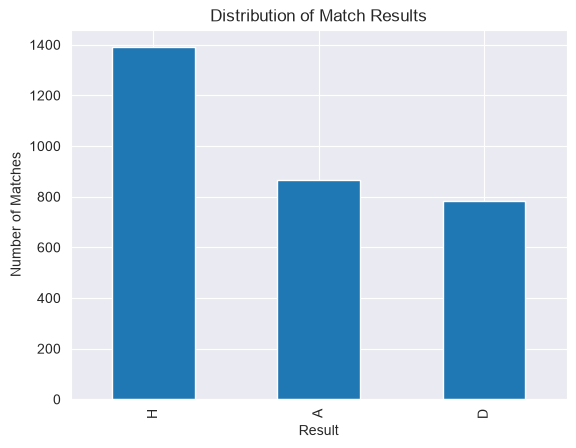

In [42]:

matches["result"].value_counts().plot(kind="bar")
plt.title("Distribution of Match Results")
plt.xlabel("Result")
plt.ylabel("Number of Matches")
plt.show()

مسئله یک Multi-class Classification با سه کلاس است

In [43]:
missing = matches.isnull().sum().sort_values(ascending=False)
print(missing.head(30))

PSH               1521
PSA               1521
PSD               1521
GBH               1141
GBD               1141
GBA               1141
BSH               1140
BSD               1140
BSA               1140
SJD                720
SJH                720
SJA                720
away_player_10       8
away_player_2        8
home_player_2        7
home_player_8        7
away_player_7        7
away_player_5        7
home_player_10       7
away_player_9        6
away_player_11       5
home_player_7        5
away_player_6        4
home_player_5        3
IWD                  2
away_player_8        2
IWH                  2
IWA                  2
home_player_9        2
BWH                  1
dtype: int64


In [44]:
print(matches.duplicated(subset=["match_api_id"]).sum())

0


In [45]:
matches["date"] = pd.to_datetime(matches["date"])
matches = matches.sort_values("date").reset_index(drop=True)

In [46]:
matches = matches.dropna(
    subset=["home_team_goal", "away_team_goal"]
)

مرحله ۶: جلوگیری از Data Leakage

این ستون‌ها را به‌عنوان ورودی مدل استفاده نکن:

home_team_goal
away_team_goal
goal
shoton
shotoff
corner
foulcommit
card
cross
possession

In [47]:
print(matches.shape)
print(matches.head())
print(matches.info())

مسئله یک Multi-class Classification با سه کلاس است

In [51]:
missing = matches.isnull().sum().sort_values(ascending=False)
print(missing.head(30))

PSH               1521
PSA               1521
PSD               1521
GBH               1141
GBD               1141
GBA               1141
BSH               1140
BSD               1140
BSA               1140
SJD                720
SJH                720
SJA                720
away_player_10       8
away_player_2        8
home_player_2        7
home_player_8        7
away_player_7        7
away_player_5        7
home_player_10       7
away_player_9        6
away_player_11       5
home_player_7        5
away_player_6        4
home_player_5        3
IWD                  2
away_player_8        2
IWH                  2
IWA                  2
home_player_9        2
BWH                  1
dtype: int64


In [52]:
print(matches.duplicated(subset=["match_api_id"]).sum())

0


In [53]:
matches["date"] = pd.to_datetime(matches["date"])
matches = matches.sort_values("date").reset_index(drop=True)

In [54]:
matches = matches.dropna(
    subset=["home_team_goal", "away_team_goal"]
)

Arsenal 2 - 1 Chelsea

برای Arsenal می‌شود:

team_name = Arsenal
opponent_name = Chelsea
goals_for = 2
goals_against = 1

In [56]:
# Build team-level match history from the perspective of each team

home_history = matches[[
    "match_api_id", "date", "season",
    "home_team_api_id", "away_team_api_id",
    "home_team", "away_team",
    "home_team_goal", "away_team_goal"
]].copy()

home_history = home_history.rename(columns={
    "home_team_api_id": "team_api_id",
    "away_team_api_id": "opponent_api_id",
    "home_team": "team_name",
    "away_team": "opponent_name",
    "home_team_goal": "goals_for",
    "away_team_goal": "goals_against"
})

home_history["is_home"] = 1


away_history = matches[[
    "match_api_id", "date", "season",
    "away_team_api_id", "home_team_api_id",
    "away_team", "home_team",
    "away_team_goal", "home_team_goal"
]].copy()

away_history = away_history.rename(columns={
    "away_team_api_id": "team_api_id",
    "home_team_api_id": "opponent_api_id",
    "away_team": "team_name",
    "home_team": "opponent_name",
    "away_team_goal": "goals_for",
    "home_team_goal": "goals_against"
})

away_history["is_home"] = 0


team_history = pd.concat([home_history, away_history], ignore_index=True)
team_history = team_history.sort_values(["team_api_id", "date"]).reset_index(drop=True)

team_history.head()

,match_api_id,date,season,team_api_id,opponent_api_id,team_name,opponent_name,goals_for,goals_against,is_home
0,658581,2009-08-15,2009/2010,8191,10194,Burnley,Stoke City,0,2,0
1,658589,2009-08-19,2009/2010,8191,10260,Burnley,Manchester United,1,0,1
2,658601,2009-08-23,2009/2010,8191,8668,Burnley,Everton,1,0,1
3,658612,2009-08-29,2009/2010,8191,8455,Burnley,Chelsea,0,3,0
4,658613,2009-09-12,2009/2010,8191,8650,Burnley,Liverpool,0,4,0


In [57]:
def calculate_points(row):
    if row["goals_for"] > row["goals_against"]:
        return 3
    elif row["goals_for"] == row["goals_against"]:
        return 1
    else:
        return 0

team_history["points"] = team_history.apply(calculate_points, axis=1)
team_history["win"] = (team_history["points"] == 3).astype(int)
team_history["draw"] = (team_history["points"] == 1).astype(int)
team_history["loss"] = (team_history["points"] == 0).astype(int)

team_history[[
    "date", "team_name", "opponent_name",
    "is_home", "goals_for", "goals_against",
    "points", "win", "draw", "loss"
]].head()

,date,team_name,opponent_name,is_home,goals_for,goals_against,points,win,draw,loss
0,2009-08-15,Burnley,Stoke City,0,0,2,0,0,0,1
1,2009-08-19,Burnley,Manchester United,1,1,0,3,1,0,0
2,2009-08-23,Burnley,Everton,1,1,0,3,1,0,0
3,2009-08-29,Burnley,Chelsea,0,0,3,0,0,0,1
4,2009-09-12,Burnley,Liverpool,0,0,4,0,0,0,1


  شروع فیچر انخاب کردن


In [58]:
team_history = team_history.sort_values(["team_api_id", "date"]).reset_index(drop=True)

team_history["points_last5"] = (
    team_history
    .groupby("team_api_id")["points"]
    .transform(lambda x: x.shift(1).rolling(5, min_periods=1).sum())
)

team_history["goals_for_last5"] = (
    team_history
    .groupby("team_api_id")["goals_for"]
    .transform(lambda x: x.shift(1).rolling(5, min_periods=1).mean())
)
# یعنی بازی فعلی را وارد محاسبه نکن
team_history["goals_against_last5"] = (
    team_history
    .groupby("team_api_id")["goals_against"]
    .transform(lambda x: x.shift(1).rolling(5, min_periods=1).mean())
)

team_history["wins_last5"] = (
    team_history
    .groupby("team_api_id")["win"]
    .transform(lambda x: x.shift(1).rolling(5, min_periods=1).sum())
)

team_history["draws_last5"] = (
    team_history
    .groupby("team_api_id")["draw"]
    .transform(lambda x: x.shift(1).rolling(5, min_periods=1).sum())
)

team_history["losses_last5"] = (
    team_history
    .groupby("team_api_id")["loss"]
    .transform(lambda x: x.shift(1).rolling(5, min_periods=1).sum())
)

team_history["previous_match_date"] = (
    team_history
    .groupby("team_api_id")["date"]
    .shift(1)
)

team_history["rest_days"] = (
    team_history["date"] - team_history["previous_match_date"]
).dt.days

team_history.head()

,match_api_id,date,season,team_api_id,opponent_api_id,team_name,opponent_name,goals_for,goals_against,is_home,...,draw,loss,points_last5,goals_for_last5,goals_against_last5,wins_last5,draws_last5,losses_last5,previous_match_date,rest_days
0,658581,2009-08-15,2009/2010,8191,10194,Burnley,Stoke City,0,2,0,...,0,1,NaN,NaN,NaN,NaN,NaN,NaN,NaT,NaN
1,658589,2009-08-19,2009/2010,8191,10260,Burnley,Manchester United,1,0,1,...,0,0,0.0,0.000000,2.000000,0.0,0.0,1.0,2009-08-15,4.0
2,658601,2009-08-23,2009/2010,8191,8668,Burnley,Everton,1,0,1,...,0,0,3.0,0.500000,1.000000,1.0,0.0,1.0,2009-08-19,4.0
3,658612,2009-08-29,2009/2010,8191,8455,Burnley,Chelsea,0,3,0,...,0,1,6.0,0.666667,0.666667,2.0,0.0,1.0,2009-08-23,6.0
4,658613,2009-09-12,2009/2010,8191,8650,Burnley,Liverpool,0,4,0,...,0,1,6.0,0.500000,1.250000,2.0,0.0,2.0,2009-08-29,14.0


In [59]:
form_columns = [
    "match_api_id",
    "points_last5",
    "goals_for_last5",
    "goals_against_last5",
    "wins_last5",
    "draws_last5",
    "losses_last5",
    "rest_days"
]

home_form = team_history[team_history["is_home"] == 1][form_columns].copy()
away_form = team_history[team_history["is_home"] == 0][form_columns].copy()

home_form = home_form.rename(columns={
    "points_last5": "home_points_last5",
    "goals_for_last5": "home_goals_for_last5",
    "goals_against_last5": "home_goals_against_last5",
    "wins_last5": "home_wins_last5",
    "draws_last5": "home_draws_last5",
    "losses_last5": "home_losses_last5",
    "rest_days": "home_rest_days"
})

away_form = away_form.rename(columns={
    "points_last5": "away_points_last5",
    "goals_for_last5": "away_goals_for_last5",
    "goals_against_last5": "away_goals_against_last5",
    "wins_last5": "away_wins_last5",
    "draws_last5": "away_draws_last5",
    "losses_last5": "away_losses_last5",
    "rest_days": "away_rest_days"
})

df = matches.merge(home_form, on="match_api_id", how="left")
df = df.merge(away_form, on="match_api_id", how="left")

df.head()

,id,country_id,league_id,season,stage,date,match_api_id,home_team_api_id,away_team_api_id,home_team_goal,...,home_draws_last5,home_losses_last5,home_rest_days,away_points_last5,away_goals_for_last5,away_goals_against_last5,away_wins_last5,away_draws_last5,away_losses_last5,away_rest_days
0,1730,1729,1729,2008/2009,1,2008-08-16,489043,9825,8659,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1731,1729,1729,2008/2009,1,2008-08-16,489044,8472,8650,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1732,1729,1729,2008/2009,1,2008-08-16,489045,8654,8528,2,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1734,1729,1729,2008/2009,1,2008-08-16,489047,8668,8655,2,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1735,1729,1729,2008/2009,1,2008-08-16,489048,8549,8586,2,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


 اختلاف هارو پیدا میکنیم

In [60]:
df["form_difference"] = df["home_points_last5"] - df["away_points_last5"]

df["attack_difference"] = (
    df["home_goals_for_last5"] -
    df["away_goals_for_last5"]
)
# اینجا برعکس کم کردن را طوری نوشتیم که اگر عدد مثبت شود، یعنی دفاع میزبان بهتر بوده
df["defense_difference"] = (
    df["away_goals_against_last5"] -
    df["home_goals_against_last5"]
)

df["win_difference"] = df["home_wins_last5"] - df["away_wins_last5"]

df["rest_difference"] = df["home_rest_days"] - df["away_rest_days"]

df[[
    "home_team", "away_team", "result",
    "home_points_last5", "away_points_last5",
    "form_difference",
    "attack_difference",
    "defense_difference"
]].head()

,home_team,away_team,result,home_points_last5,away_points_last5,form_difference,attack_difference,defense_difference
0,Arsenal,West Bromwich Albion,H,NaN,NaN,NaN,NaN,NaN
1,Sunderland,Liverpool,A,NaN,NaN,NaN,NaN,NaN
2,West Ham United,Wigan Athletic,H,NaN,NaN,NaN,NaN,NaN
3,Everton,Blackburn Rovers,A,NaN,NaN,NaN,NaN,NaN
4,Middlesbrough,Tottenham Hotspur,H,NaN,NaN,NaN,NaN,NaN


In [61]:
form_feature_columns = [
    "home_points_last5",
    "away_points_last5",
    "home_goals_for_last5",
    "away_goals_for_last5",
    "home_goals_against_last5",
    "away_goals_against_last5",
    "home_wins_last5",
    "away_wins_last5",
    "home_draws_last5",
    "away_draws_last5",
    "home_losses_last5",
    "away_losses_last5",
    "home_rest_days",
    "away_rest_days",
    "form_difference",
    "attack_difference",
    "defense_difference",
    "win_difference",
    "rest_difference"
]

df[form_feature_columns] = df[form_feature_columns].fillna(0)

df[form_feature_columns].isnull().sum()

home_points_last5           0
away_points_last5           0
home_goals_for_last5        0
away_goals_for_last5        0
home_goals_against_last5    0
away_goals_against_last5    0
home_wins_last5             0
away_wins_last5             0
home_draws_last5            0
away_draws_last5            0
home_losses_last5           0
away_losses_last5           0
home_rest_days              0
away_rest_days              0
form_difference             0
attack_difference           0
defense_difference          0
win_difference              0
rest_difference             0
dtype: int64

In [62]:
df[form_feature_columns].describe()

,home_points_last5,away_points_last5,home_goals_for_last5,away_goals_for_last5,home_goals_against_last5,away_goals_against_last5,home_wins_last5,away_wins_last5,home_draws_last5,away_draws_last5,home_losses_last5,away_losses_last5,home_rest_days,away_rest_days,form_difference,attack_difference,defense_difference,win_difference,rest_difference
count,3040.000000,3040.000000,3040.000000,3040.000000,3040.000000,3040.000000,3040.000000,3040.000000,3040.000000,3040.000000,3040.000000,3040.000000,3040.000000,3040.000000,3040.000000,3040.000000,3040.000000,3040.000000,3040.000000
mean,6.650329,6.882237,1.328503,1.361447,1.367231,1.317242,1.796711,1.873684,1.260197,1.261184,1.859539,1.780921,9.971711,9.671711,-0.245066,-0.034852,-0.050186,-0.081250,0.244408
std,3.390233,3.355333,0.644546,0.660023,0.615317,0.602652,1.212848,1.207563,0.978745,0.966129,1.192692,1.166621,33.621177,27.042131,4.587507,0.893785,0.834676,1.663234,36.429007
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-14.000000,-4.000000,-3.400000,-5.000000,-1106.000000
25%,4.000000,4.000000,0.800000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,6.000000,6.000000,-3.000000,-0.600000,-0.600000,-1.000000,-1.000000
50%,7.000000,7.000000,1.200000,1.200000,1.400000,1.200000,2.000000,2.000000,1.000000,1.000000,2.000000,2.000000,7.000000,7.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,9.000000,9.000000,1.600000,1.800000,1.800000,1.600000,3.000000,3.000000,2.000000,2.000000,3.000000,3.000000,8.000000,8.000000,3.000000,0.600000,0.400000,1.000000,1.000000
max,15.000000,15.000000,5.800000,4.800000,4.000000,4.600000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,1562.000000,1197.000000,14.000000,5.200000,3.600000,5.000000,1463.000000


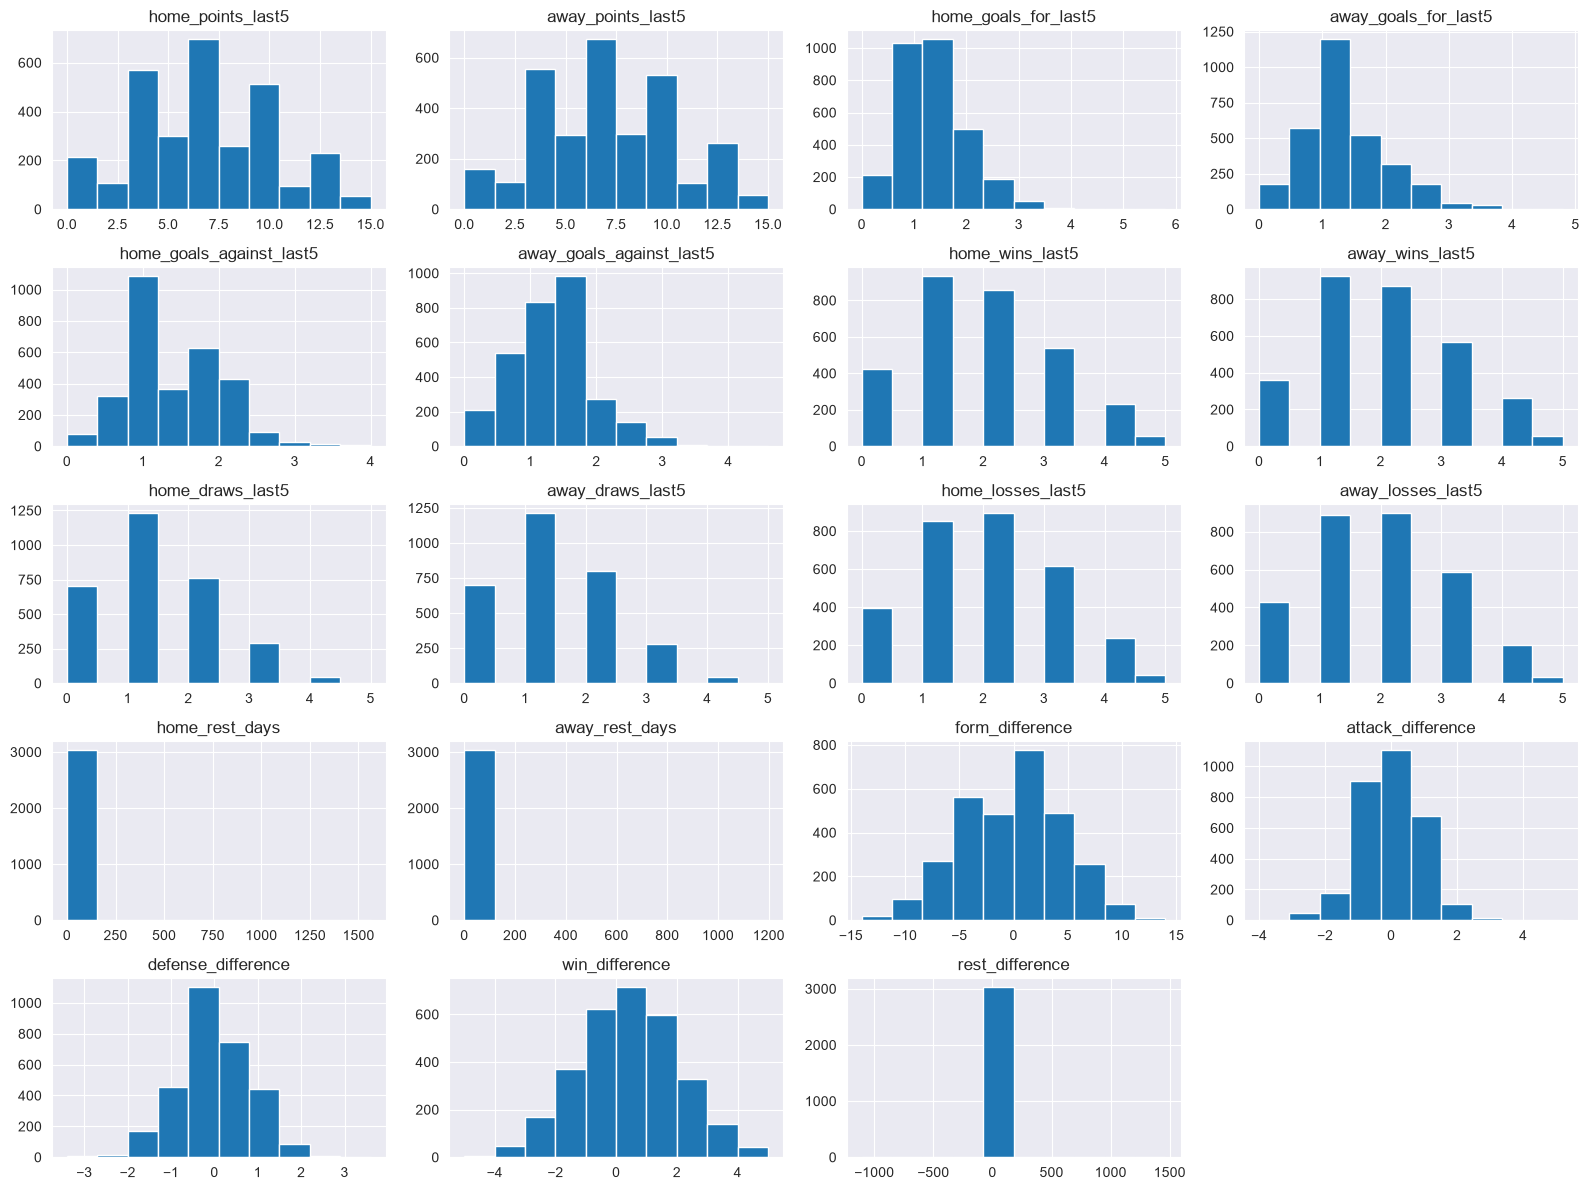

In [63]:
df[form_feature_columns].hist(figsize=(16, 12))
plt.tight_layout()
plt.show()

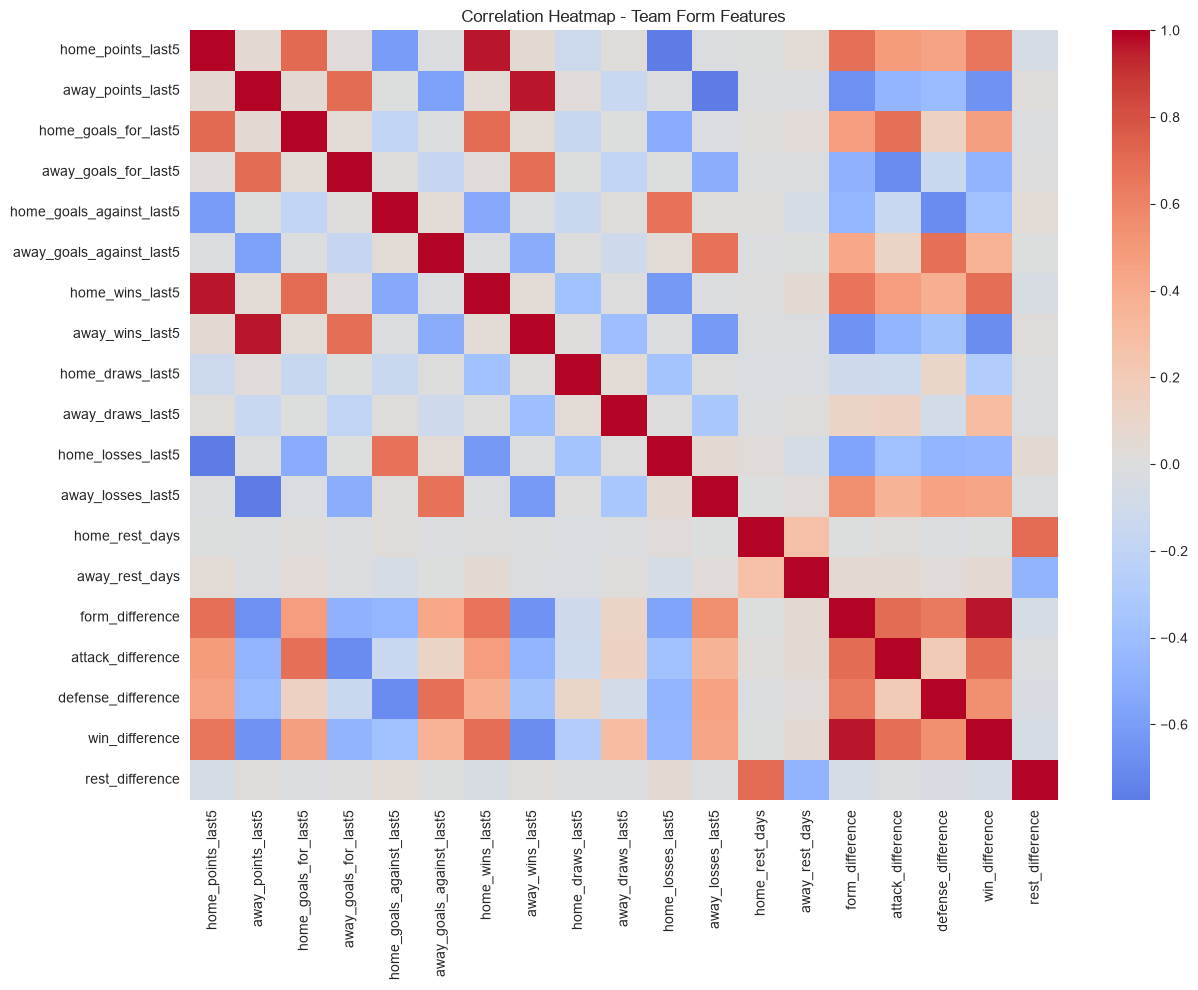

In [64]:
plt.figure(figsize=(14, 10))
sns.heatmap(
    df[form_feature_columns].corr(),
    cmap="coolwarm",
    center=0
)
plt.title("Correlation Heatmap - Team Form Features")
plt.show()

بعضی فیچرها مثل points_last5 و wins_last5 ممکن است همبستگی بالایی داشته باشند، چون هر دو فرم اخیر تیم را نشان می‌دهند.

In [65]:
feature_columns_base = [
    "home_points_last5",
    "away_points_last5",
    "home_goals_for_last5",
    "away_goals_for_last5",
    "home_goals_against_last5",
    "away_goals_against_last5",
    "home_wins_last5",
    "away_wins_last5",
    "home_rest_days",
    "away_rest_days",
    "form_difference",
    "attack_difference",
    "defense_difference",
    "win_difference",
    "rest_difference"
]

model_df_base = df[[
    "date", "season", "home_team", "away_team", "result"
] + feature_columns_base].copy()

model_df_base = model_df_base.sort_values("date").reset_index(drop=True)

model_df_base.head()

,date,season,home_team,away_team,result,home_points_last5,away_points_last5,home_goals_for_last5,away_goals_for_last5,home_goals_against_last5,away_goals_against_last5,home_wins_last5,away_wins_last5,home_rest_days,away_rest_days,form_difference,attack_difference,defense_difference,win_difference,rest_difference
0,2008-08-16,2008/2009,Arsenal,West Bromwich Albion,H,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2008-08-16,2008/2009,Sunderland,Liverpool,A,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,2008-08-16,2008/2009,West Ham United,Wigan Athletic,H,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,2008-08-16,2008/2009,Everton,Blackburn Rovers,A,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,2008-08-16,2008/2009,Middlesbrough,Tottenham Hotspur,H,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


چون فوتبال داده زمانی است، بهتر است Random Split نکنی.

In [66]:
print(model_df_base["season"].unique())

<StringArray>
['2008/2009', '2009/2010', '2010/2011', '2011/2012', '2012/2013', '2013/2014',
 '2014/2015', '2015/2016']
Length: 8, dtype: str


In [67]:
train_df = model_df_base[
    model_df_base["season"].isin([
        "2008/2009",
        "2009/2010",
        "2010/2011",
        "2011/2012",
        "2012/2013",
        "2013/2014"
    ])
]

valid_df = model_df_base[
    model_df_base["season"] == "2014/2015"
]

test_df = model_df_base[
    model_df_base["season"] == "2015/2016"
]

X_train = train_df[feature_columns_base]
y_train = train_df["result"]

X_valid = valid_df[feature_columns_base]
y_valid = valid_df["result"]

X_test = test_df[feature_columns_base]
y_test = test_df["result"]

print("Train:", X_train.shape)
print("Validation:", X_valid.shape)
print("Test:", X_test.shape)

Train: (2280, 15)
Validation: (380, 15)
Test: (380, 15)


In [68]:
def evaluate_model(name, model, X_train, y_train, X_test, y_test):
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    acc = accuracy_score(y_test, predictions)
    macro_f1 = f1_score(y_test, predictions, average="macro")

    print("=" * 60)
    print(name)
    print("Accuracy:", acc)
    print("Macro F1:", macro_f1)
    print()
    print(classification_report(y_test, predictions))

    cm = confusion_matrix(y_test, predictions, labels=["H", "D", "A"])

    plt.figure(figsize=(5, 4))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        xticklabels=["Home Win", "Draw", "Away Win"],
        yticklabels=["Home Win", "Draw", "Away Win"]
    )
    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

    return {
        "Model": name,
        "Accuracy": acc,
        "Macro F1": macro_f1
    }

Dummy Baseline
Accuracy: 0.4131578947368421
Macro F1: 0.19490999379267537

              precision    recall  f1-score   support

           A       0.00      0.00      0.00       116
           D       0.00      0.00      0.00       107
           H       0.41      1.00      0.58       157

    accuracy                           0.41       380
   macro avg       0.14      0.33      0.19       380
weighted avg       0.17      0.41      0.24       380



C:\Users\ghazal\PycharmProjects\PythonProject16\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\ghazal\PycharmProjects\PythonProject16\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\ghazal\PycharmProjects\PythonProject16\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(averag

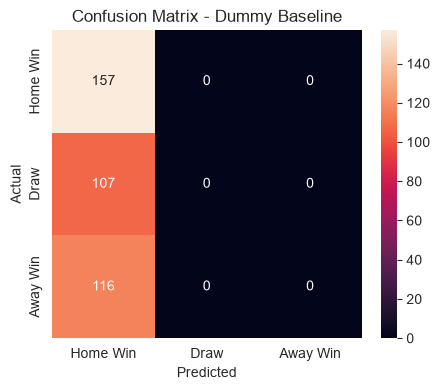

KNN
Accuracy: 0.35789473684210527
Macro F1: 0.3318191005626001

              precision    recall  f1-score   support

           A       0.34      0.37      0.35       116
           D       0.22      0.16      0.18       107
           H       0.44      0.48      0.46       157

    accuracy                           0.36       380
   macro avg       0.33      0.34      0.33       380
weighted avg       0.34      0.36      0.35       380



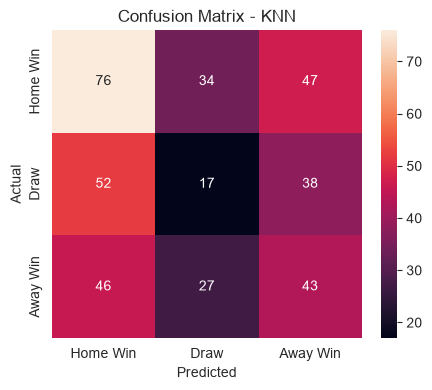

Logistic Regression
Accuracy: 0.4
Macro F1: 0.371885993175274

              precision    recall  f1-score   support

           A       0.40      0.41      0.40       116
           D       0.22      0.18      0.20       107
           H       0.49      0.55      0.52       157

    accuracy                           0.40       380
   macro avg       0.37      0.38      0.37       380
weighted avg       0.39      0.40      0.39       380



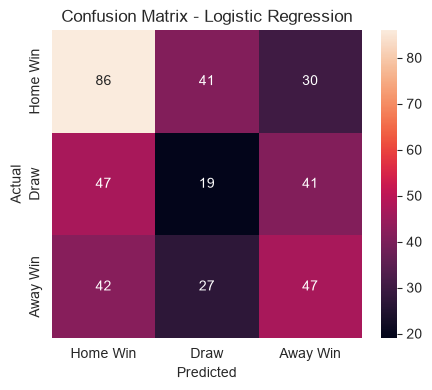

Random Forest
Accuracy: 0.37105263157894736
Macro F1: 0.3464190040893939

              precision    recall  f1-score   support

           A       0.36      0.36      0.36       116
           D       0.18      0.17      0.18       107
           H       0.49      0.52      0.50       157

    accuracy                           0.37       380
   macro avg       0.34      0.35      0.35       380
weighted avg       0.36      0.37      0.37       380



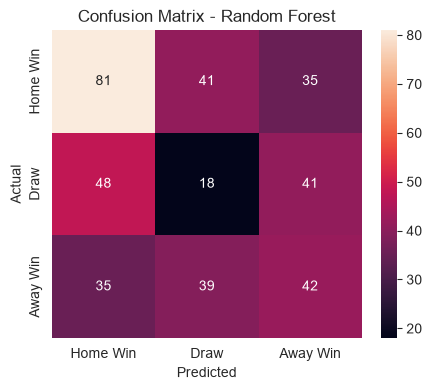

Gradient Boosting
Accuracy: 0.4368421052631579
Macro F1: 0.3365754223012259

              precision    recall  f1-score   support

           A       0.42      0.28      0.33       116
           D       0.26      0.06      0.09       107
           H       0.46      0.82      0.59       157

    accuracy                           0.44       380
   macro avg       0.38      0.38      0.34       380
weighted avg       0.39      0.44      0.37       380



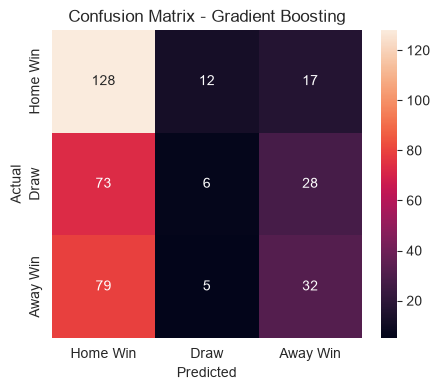

,Model,Accuracy,Macro F1
0,Dummy Baseline,0.413158,0.194910
1,KNN,0.357895,0.331819
2,Logistic Regression,0.400000,0.371886
3,Random Forest,0.371053,0.346419
4,Gradient Boosting,0.436842,0.336575


In [69]:
models = {
    "Dummy Baseline": DummyClassifier(strategy="most_frequent"),

    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=5))
    ]),

    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=42
        ))
    ]),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        max_depth=12,
        min_samples_split=5,
        random_state=42,
        class_weight="balanced"
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    )
}

results_base = []

for name, model in models.items():
    result = evaluate_model(
        name,
        model,
        X_train,
        y_train,
        X_test,
        y_test
    )
    results_base.append(result)

results_base_df = pd.DataFrame(results_base)
results_base_df

In [70]:
results_base_df.sort_values("Macro F1", ascending=False)

,Model,Accuracy,Macro F1
2,Logistic Regression,0.400000,0.371886
3,Random Forest,0.371053,0.346419
4,Gradient Boosting,0.436842,0.336575
1,KNN,0.357895,0.331819
0,Dummy Baseline,0.413158,0.194910


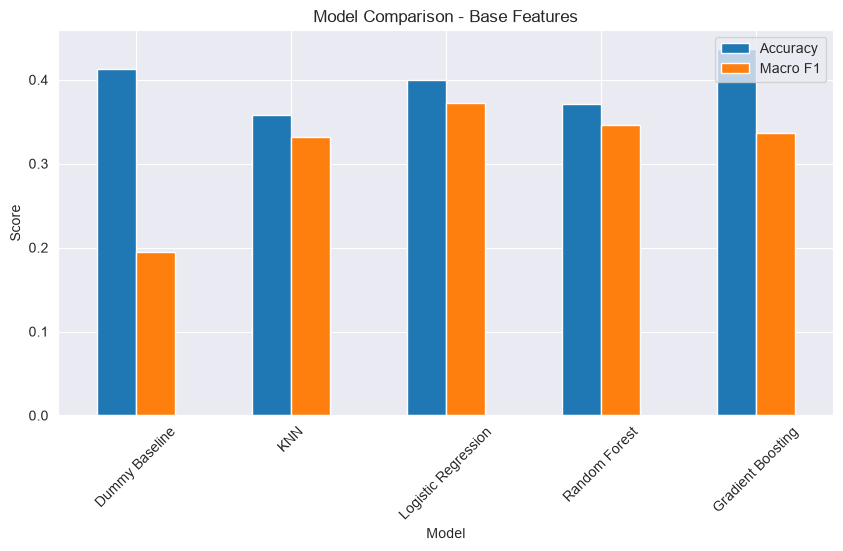

In [71]:
results_base_df.set_index("Model")[["Accuracy", "Macro F1"]].plot(kind="bar", figsize=(10, 5))
plt.title("Model Comparison - Base Features")
plt.ylabel("Score")
plt.xticks(rotation=45)
plt.show()


LINEUP مرحله ۲

In [72]:
player_attributes = pd.read_sql("""
SELECT
    player_api_id,
    date,
    overall_rating
FROM Player_Attributes
WHERE overall_rating IS NOT NULL;
""", conn)

player_attributes["date"] = pd.to_datetime(player_attributes["date"])
player_attributes = player_attributes.sort_values(["player_api_id", "date"])

player_attributes.head()

,player_api_id,date,overall_rating
139205,2625,2007-02-22,63
139204,2625,2007-08-30,63
139203,2625,2008-08-30,60
139202,2625,2010-08-30,60
139201,2625,2011-02-22,59


In [73]:
home_player_cols = [f"home_player_{i}" for i in range(1, 12)]
away_player_cols = [f"away_player_{i}" for i in range(1, 12)]

home_lineup = matches[["match_api_id", "date"] + home_player_cols].copy()
home_lineup = home_lineup.melt(
    id_vars=["match_api_id", "date"],
    value_vars=home_player_cols,
    var_name="player_position",
    value_name="player_api_id"
)
home_lineup["side"] = "home"
home_lineup["position_number"] = home_lineup["player_position"].str.extract(r"(\d+)").astype(int)

away_lineup = matches[["match_api_id", "date"] + away_player_cols].copy()
away_lineup = away_lineup.melt(
    id_vars=["match_api_id", "date"],
    value_vars=away_player_cols,
    var_name="player_position",
    value_name="player_api_id"
)
away_lineup["side"] = "away"
away_lineup["position_number"] = away_lineup["player_position"].str.extract(r"(\d+)").astype(int)

lineup_long = pd.concat([home_lineup, away_lineup], ignore_index=True)
lineup_long["date"] = pd.to_datetime(lineup_long["date"])

lineup_long = lineup_long.dropna(subset=["player_api_id"])
lineup_long["player_api_id"] = lineup_long["player_api_id"].astype(int)

lineup_long.head()

,match_api_id,date,player_position,player_api_id,side,position_number
0,489043,2008-08-16,home_player_1,23686,home,1
1,489044,2008-08-16,home_player_1,32562,home,1
2,489045,2008-08-16,home_player_1,36374,home,1
3,489047,2008-08-16,home_player_1,31465,home,1
4,489048,2008-08-16,home_player_1,35442,home,1


In [74]:
def add_latest_player_rating(lineup_data, attributes_data):
    result_parts = []

    for player_id, player_matches in lineup_data.groupby("player_api_id"):
        player_matches = player_matches.sort_values("date")

        player_attr = attributes_data[
            attributes_data["player_api_id"] == player_id
        ].sort_values("date")

        if player_attr.empty:
            player_matches["overall_rating"] = np.nan
            result_parts.append(player_matches)
            continue

        merged = pd.merge_asof(
            player_matches,
            player_attr[["date", "overall_rating"]],
            on="date",
            direction="backward"
        )

        result_parts.append(merged)

    return pd.concat(result_parts, ignore_index=True)

lineup_with_rating = add_latest_player_rating(lineup_long, player_attributes)

lineup_with_rating.head()

,match_api_id,date,player_position,player_api_id,side,position_number,overall_rating
0,1228380,2012-09-22,home_player_8,2802,home,8,76
1,1228544,2012-09-29,away_player_10,2802,away,10,76
2,1229180,2012-10-20,home_player_10,2802,home,10,76
3,1229190,2012-10-27,away_player_10,2802,away,10,76
4,1229202,2012-11-03,home_player_10,2802,home,10,76


In [75]:
def position_group(position_number):
    if position_number == 1:
        return "goalkeeper"
    elif position_number <= 5:
        return "defense"
    elif position_number <= 8:
        return "midfield"
    else:
        return "attack"

lineup_with_rating["position_group"] = lineup_with_rating["position_number"].apply(position_group)

lineup_with_rating[[
    "match_api_id", "side", "position_number",
    "position_group", "player_api_id", "overall_rating"
]].head()

,match_api_id,side,position_number,position_group,player_api_id,overall_rating
0,1228380,home,8,midfield,2802,76
1,1228544,away,10,attack,2802,76
2,1229180,home,10,attack,2802,76
3,1229190,away,10,attack,2802,76
4,1229202,home,10,attack,2802,76


In [76]:
lineup_summary = (
    lineup_with_rating
    .groupby(["match_api_id", "side"])
    .agg(
        lineup_avg_rating=("overall_rating", "mean"),
        lineup_max_rating=("overall_rating", "max"),
        lineup_min_rating=("overall_rating", "min"),
        known_players=("overall_rating", "count")
    )
    .reset_index()
)

lineup_summary.head()

,match_api_id,side,lineup_avg_rating,lineup_max_rating,lineup_min_rating,known_players
0,489042,away,75.272727,83,56,11
1,489042,home,82.454545,90,74,11
2,489043,away,71.181818,79,63,11
3,489043,home,78.000000,87,72,11
4,489044,away,79.909091,89,60,11


In [77]:
line_group_summary = (
    lineup_with_rating
    .groupby(["match_api_id", "side", "position_group"])["overall_rating"]
    .mean()
    .reset_index()
)

line_group_pivot = line_group_summary.pivot_table(
    index=["match_api_id", "side"],
    columns="position_group",
    values="overall_rating"
).reset_index()

lineup_features = lineup_summary.merge(
    line_group_pivot,
    on=["match_api_id", "side"],
    how="left"
)

lineup_features.head()

,match_api_id,side,lineup_avg_rating,lineup_max_rating,lineup_min_rating,known_players,attack,defense,goalkeeper,midfield
0,489042,away,75.272727,83,56,11,78.000000,77.50,82.0,67.333333
1,489042,home,82.454545,90,74,11,83.333333,82.50,85.0,80.666667
2,489043,away,71.181818,79,63,11,71.333333,69.25,77.0,71.666667
3,489043,home,78.000000,87,72,11,81.666667,78.00,75.0,75.333333
4,489044,away,79.909091,89,60,11,83.666667,75.25,84.0,81.000000


In [78]:
home_lineup_features = lineup_features[lineup_features["side"] == "home"].copy()
away_lineup_features = lineup_features[lineup_features["side"] == "away"].copy()

home_lineup_features = home_lineup_features.drop(columns=["side"])
away_lineup_features = away_lineup_features.drop(columns=["side"])

home_lineup_features = home_lineup_features.add_prefix("home_")
away_lineup_features = away_lineup_features.add_prefix("away_")

home_lineup_features = home_lineup_features.rename(columns={
    "home_match_api_id": "match_api_id"
})

away_lineup_features = away_lineup_features.rename(columns={
    "away_match_api_id": "match_api_id"
})

df2 = df.merge(home_lineup_features, on="match_api_id", how="left")
df2 = df2.merge(away_lineup_features, on="match_api_id", how="left")

df2.head()

,id,country_id,league_id,season,stage,date,match_api_id,home_team_api_id,away_team_api_id,home_team_goal,...,home_goalkeeper,home_midfield,away_lineup_avg_rating,away_lineup_max_rating,away_lineup_min_rating,away_known_players,away_attack,away_defense,away_goalkeeper,away_midfield
0,1730,1729,1729,2008/2009,1,2008-08-16,489043,9825,8659,1,...,75.0,75.333333,71.181818,79,63,11,71.333333,69.25,77.0,71.666667
1,1731,1729,1729,2008/2009,1,2008-08-16,489044,8472,8650,0,...,78.0,77.333333,79.909091,89,60,11,83.666667,75.25,84.0,81.000000
2,1732,1729,1729,2008/2009,1,2008-08-16,489045,8654,8528,2,...,77.0,77.000000,73.272727,79,67,11,75.666667,72.00,77.0,71.333333
3,1734,1729,1729,2008/2009,1,2008-08-16,489047,8668,8655,2,...,79.0,75.666667,77.636364,85,73,11,77.333333,77.00,81.0,77.666667
4,1735,1729,1729,2008/2009,1,2008-08-16,489048,8549,8586,2,...,72.0,73.000000,79.090909,85,71,11,81.000000,78.25,81.0,77.666667


In [79]:
df2["lineup_rating_difference"] = (
    df2["home_lineup_avg_rating"] -
    df2["away_lineup_avg_rating"]
)

df2["attack_rating_difference"] = (
    df2["home_attack"] -
    df2["away_attack"]
)

df2["midfield_rating_difference"] = (
    df2["home_midfield"] -
    df2["away_midfield"]
)

df2["defense_rating_difference"] = (
    df2["home_defense"] -
    df2["away_defense"]
)

df2["goalkeeper_rating_difference"] = (
    df2["home_goalkeeper"] -
    df2["away_goalkeeper"]
)

lineup_feature_columns = [
    "home_lineup_avg_rating",
    "away_lineup_avg_rating",
    "home_lineup_max_rating",
    "away_lineup_max_rating",
    "home_known_players",
    "away_known_players",
    "home_goalkeeper",
    "away_goalkeeper",
    "home_defense",
    "away_defense",
    "home_midfield",
    "away_midfield",
    "home_attack",
    "away_attack",
    "lineup_rating_difference",
    "attack_rating_difference",
    "midfield_rating_difference",
    "defense_rating_difference",
    "goalkeeper_rating_difference"
]

df2[lineup_feature_columns].head()

,home_lineup_avg_rating,away_lineup_avg_rating,home_lineup_max_rating,away_lineup_max_rating,home_known_players,away_known_players,home_goalkeeper,away_goalkeeper,home_defense,away_defense,home_midfield,away_midfield,home_attack,away_attack,lineup_rating_difference,attack_rating_difference,midfield_rating_difference,defense_rating_difference,goalkeeper_rating_difference
0,78.000000,71.181818,87,79,11,11,75.0,77.0,78.00,69.25,75.333333,71.666667,81.666667,71.333333,6.818182,10.333333,3.666667,8.75,-2.0
1,73.727273,79.909091,81,89,11,11,78.0,84.0,69.50,75.25,77.333333,81.000000,74.333333,83.666667,-6.181818,-9.333333,-3.666667,-5.75,-6.0
2,76.818182,73.272727,82,79,11,11,77.0,77.0,77.50,72.00,77.000000,71.333333,75.666667,75.666667,3.545455,0.000000,5.666667,5.50,0.0
3,76.909091,77.636364,82,85,11,11,79.0,81.0,77.25,77.00,75.666667,77.666667,77.000000,77.333333,-0.727273,-0.333333,-2.000000,0.25,-2.0
4,73.909091,79.090909,84,85,11,11,72.0,81.0,69.75,78.25,73.000000,77.666667,81.000000,81.000000,-5.181818,0.000000,-4.666667,-8.50,-9.0


In [80]:
df2[lineup_feature_columns].isnull().sum().sort_values(ascending=False)

home_lineup_avg_rating          0
away_lineup_avg_rating          0
home_lineup_max_rating          0
away_lineup_max_rating          0
home_known_players              0
away_known_players              0
home_goalkeeper                 0
away_goalkeeper                 0
home_defense                    0
away_defense                    0
home_midfield                   0
away_midfield                   0
home_attack                     0
away_attack                     0
lineup_rating_difference        0
attack_rating_difference        0
midfield_rating_difference      0
defense_rating_difference       0
goalkeeper_rating_difference    0
dtype: int64

In [81]:
for col in lineup_feature_columns:
    df2[col] = df2[col].fillna(df2[col].median())

df2[lineup_feature_columns].isnull().sum()

home_lineup_avg_rating          0
away_lineup_avg_rating          0
home_lineup_max_rating          0
away_lineup_max_rating          0
home_known_players              0
away_known_players              0
home_goalkeeper                 0
away_goalkeeper                 0
home_defense                    0
away_defense                    0
home_midfield                   0
away_midfield                   0
home_attack                     0
away_attack                     0
lineup_rating_difference        0
attack_rating_difference        0
midfield_rating_difference      0
defense_rating_difference       0
goalkeeper_rating_difference    0
dtype: int64

In [82]:
feature_columns_full = feature_columns_base + lineup_feature_columns

model_df_full = df2[[
    "date", "season", "home_team", "away_team", "result"
] + feature_columns_full].copy()

model_df_full = model_df_full.sort_values("date").reset_index(drop=True)

model_df_full.head()

,date,season,home_team,away_team,result,home_points_last5,away_points_last5,home_goals_for_last5,away_goals_for_last5,home_goals_against_last5,...,away_defense,home_midfield,away_midfield,home_attack,away_attack,lineup_rating_difference,attack_rating_difference,midfield_rating_difference,defense_rating_difference,goalkeeper_rating_difference
0,2008-08-16,2008/2009,Arsenal,West Bromwich Albion,H,0.0,0.0,0.0,0.0,0.0,...,69.25,75.333333,71.666667,81.666667,71.333333,6.818182,10.333333,3.666667,8.75,-2.0
1,2008-08-16,2008/2009,Sunderland,Liverpool,A,0.0,0.0,0.0,0.0,0.0,...,75.25,77.333333,81.000000,74.333333,83.666667,-6.181818,-9.333333,-3.666667,-5.75,-6.0
2,2008-08-16,2008/2009,West Ham United,Wigan Athletic,H,0.0,0.0,0.0,0.0,0.0,...,72.00,77.000000,71.333333,75.666667,75.666667,3.545455,0.000000,5.666667,5.50,0.0
3,2008-08-16,2008/2009,Everton,Blackburn Rovers,A,0.0,0.0,0.0,0.0,0.0,...,77.00,75.666667,77.666667,77.000000,77.333333,-0.727273,-0.333333,-2.000000,0.25,-2.0
4,2008-08-16,2008/2009,Middlesbrough,Tottenham Hotspur,H,0.0,0.0,0.0,0.0,0.0,...,78.25,73.000000,77.666667,81.000000,81.000000,-5.181818,0.000000,-4.666667,-8.50,-9.0


In [83]:
train_df_full = model_df_full[
    model_df_full["season"].isin([
        "2008/2009",
        "2009/2010",
        "2010/2011",
        "2011/2012",
        "2012/2013",
        "2013/2014"
    ])
]

valid_df_full = model_df_full[
    model_df_full["season"] == "2014/2015"
]

test_df_full = model_df_full[
    model_df_full["season"] == "2015/2016"
]

X_train_full = train_df_full[feature_columns_full]
y_train_full = train_df_full["result"]

X_test_full = test_df_full[feature_columns_full]
y_test_full = test_df_full["result"]

print("Train full:", X_train_full.shape)
print("Test full:", X_test_full.shape)

Train full: (2280, 34)
Test full: (380, 34)


Dummy Baseline + Lineup Features
Accuracy: 0.4131578947368421
Macro F1: 0.19490999379267537

              precision    recall  f1-score   support

           A       0.00      0.00      0.00       116
           D       0.00      0.00      0.00       107
           H       0.41      1.00      0.58       157

    accuracy                           0.41       380
   macro avg       0.14      0.33      0.19       380
weighted avg       0.17      0.41      0.24       380



C:\Users\ghazal\PycharmProjects\PythonProject16\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\ghazal\PycharmProjects\PythonProject16\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\ghazal\PycharmProjects\PythonProject16\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(averag

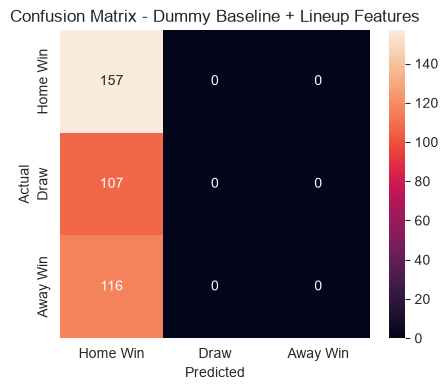

KNN + Lineup Features
Accuracy: 0.3894736842105263
Macro F1: 0.3730022129333661

              precision    recall  f1-score   support

           A       0.35      0.41      0.38       116
           D       0.29      0.24      0.27       107
           H       0.47      0.48      0.48       157

    accuracy                           0.39       380
   macro avg       0.37      0.38      0.37       380
weighted avg       0.39      0.39      0.39       380



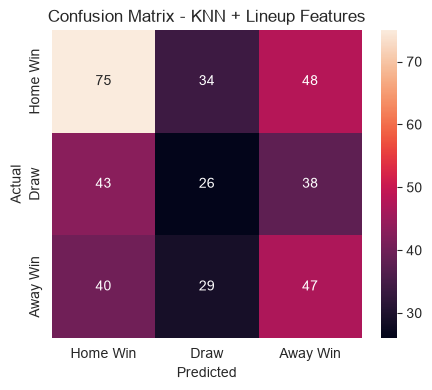

Logistic Regression + Lineup Features
Accuracy: 0.4026315789473684
Macro F1: 0.3921411956505178

              precision    recall  f1-score   support

           A       0.39      0.34      0.36       116
           D       0.28      0.35      0.31       107
           H       0.52      0.49      0.51       157

    accuracy                           0.40       380
   macro avg       0.40      0.39      0.39       380
weighted avg       0.41      0.40      0.41       380



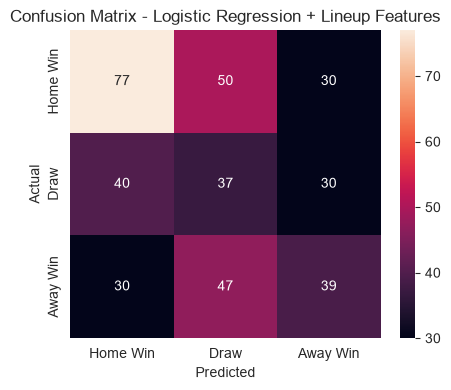

Random Forest + Lineup Features
Accuracy: 0.41578947368421054
Macro F1: 0.40272356342982535

              precision    recall  f1-score   support

           A       0.38      0.36      0.37       116
           D       0.35      0.34      0.34       107
           H       0.48      0.51      0.50       157

    accuracy                           0.42       380
   macro avg       0.40      0.40      0.40       380
weighted avg       0.41      0.42      0.41       380



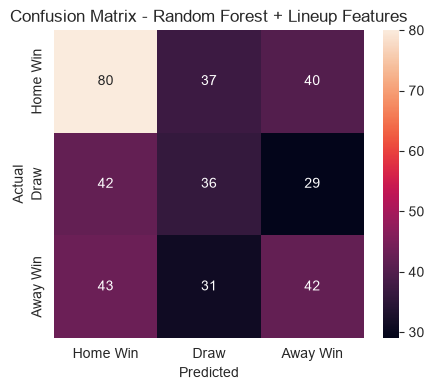

Gradient Boosting + Lineup Features
Accuracy: 0.4105263157894737
Macro F1: 0.32775916609966327

              precision    recall  f1-score   support

           A       0.38      0.29      0.33       116
           D       0.24      0.07      0.10       107
           H       0.44      0.73      0.55       157

    accuracy                           0.41       380
   macro avg       0.35      0.36      0.33       380
weighted avg       0.37      0.41      0.36       380



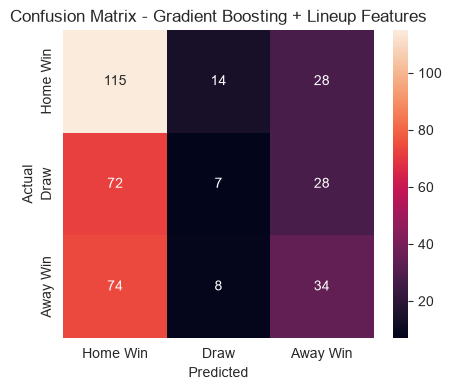

,Model,Accuracy,Macro F1
3,Random Forest + Lineup Features,0.415789,0.402724
2,Logistic Regression + Lineup Features,0.402632,0.392141
1,KNN + Lineup Features,0.389474,0.373002
4,Gradient Boosting + Lineup Features,0.410526,0.327759
0,Dummy Baseline + Lineup Features,0.413158,0.194910


In [84]:
results_full = []

for name, model in models.items():
    result = evaluate_model(
        name + " + Lineup Features",
        model,
        X_train_full,
        y_train_full,
        X_test_full,
        y_test_full
    )
    results_full.append(result)

results_full_df = pd.DataFrame(results_full)
results_full_df.sort_values("Macro F1", ascending=False)

قایسهم

In [85]:
comparison_df = pd.concat([
    results_base_df.assign(Feature_Set="Team Form Only"),
    results_full_df.assign(Feature_Set="Team Form + Lineup")
], ignore_index=True)

comparison_df.sort_values(["Model", "Feature_Set"])

,Model,Accuracy,Macro F1,Feature_Set
0,Dummy Baseline,0.413158,0.194910,Team Form Only
5,Dummy Baseline + Lineup Features,0.413158,0.194910,Team Form + Lineup
4,Gradient Boosting,0.436842,0.336575,Team Form Only
9,Gradient Boosting + Lineup Features,0.410526,0.327759,Team Form + Lineup
1,KNN,0.357895,0.331819,Team Form Only
6,KNN + Lineup Features,0.389474,0.373002,Team Form + Lineup
2,Logistic Regression,0.400000,0.371886,Team Form Only
7,Logistic Regression + Lineup Features,0.402632,0.392141,Team Form + Lineup
3,Random Forest,0.371053,0.346419,Team Form Only
8,Random Forest + Lineup Features,0.415789,0.402724,Team Form + Lineup


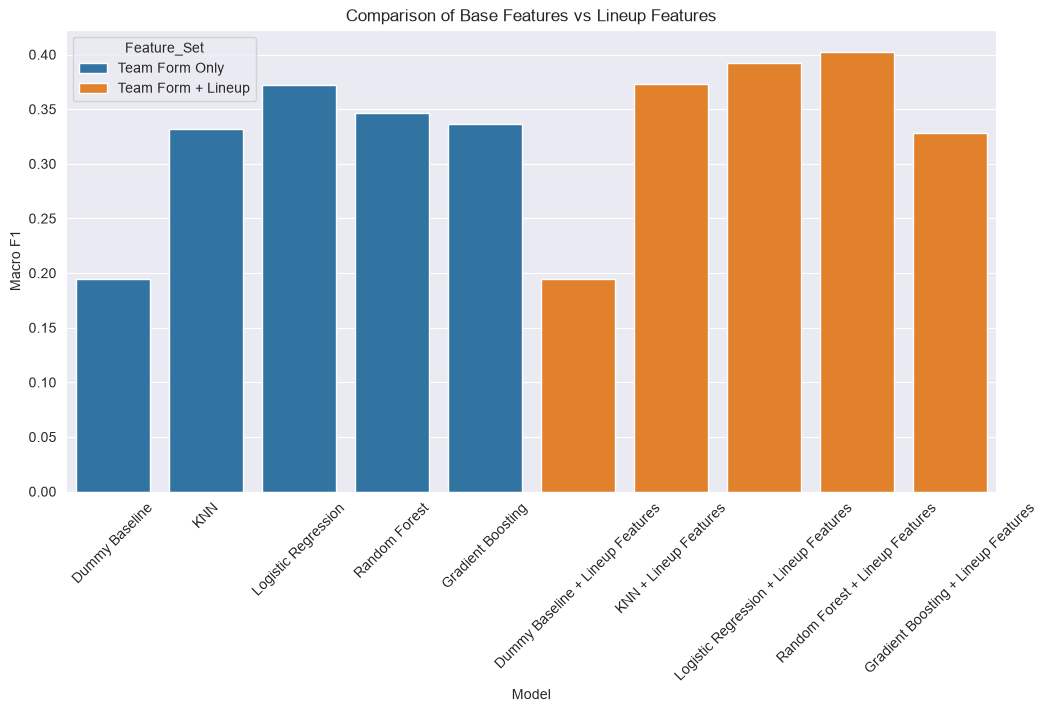

In [86]:
plt.figure(figsize=(12, 6))
sns.barplot(
    data=comparison_df,
    x="Model",
    y="Macro F1",
    hue="Feature_Set"
)
plt.title("Comparison of Base Features vs Lineup Features")
plt.xticks(rotation=45)
plt.show()

In [87]:
best_rf = RandomForestClassifier(
    n_estimators=300,
    max_depth=12,
    min_samples_split=5,
    random_state=42,
    class_weight="balanced"
)

best_rf.fit(X_train_full, y_train_full)

importance_df = pd.DataFrame({
    "Feature": feature_columns_full,
    "Importance": best_rf.feature_importances_
}).sort_values("Importance", ascending=False)

importance_df.head(15)

,Feature,Importance
29,lineup_rating_difference,0.056209
30,attack_rating_difference,0.054582
31,midfield_rating_difference,0.052492
16,away_lineup_avg_rating,0.046449
32,defense_rating_difference,0.045512
15,home_lineup_avg_rating,0.042284
25,home_midfield,0.041375
24,away_defense,0.037885
26,away_midfield,0.036796
27,home_attack,0.036753


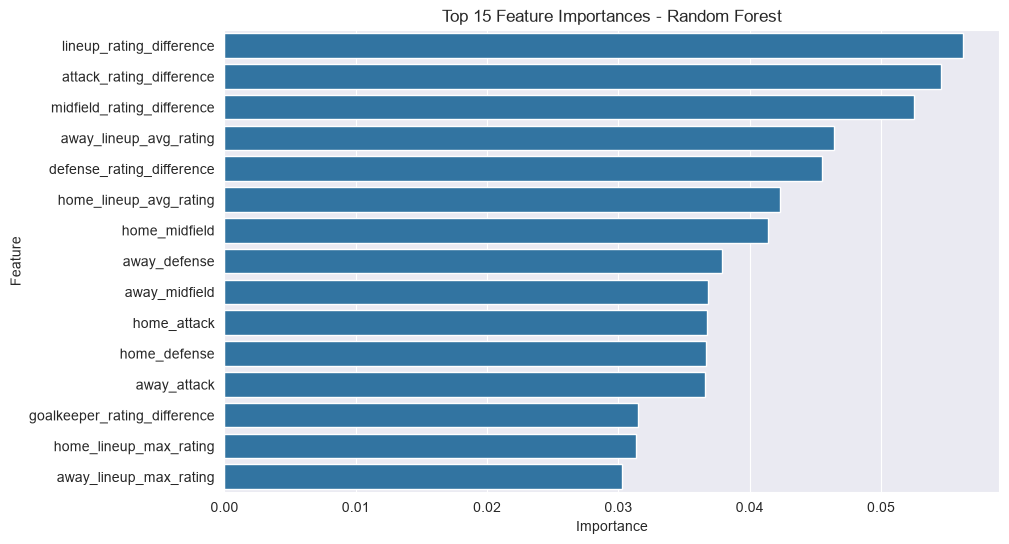

In [88]:
plt.figure(figsize=(10, 6))
sns.barplot(
    data=importance_df.head(15),
    x="Importance",
    y="Feature"
)
plt.title("Top 15 Feature Importances - Random Forest")
plt.show()

In [89]:
from sklearn.model_selection import cross_val_score

tscv = TimeSeriesSplit(n_splits=5)

rf_cv_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=12,
    min_samples_split=5,
    random_state=42,
    class_weight="balanced"
)

cv_scores = cross_val_score(
    rf_cv_model,
    X_train_full,
    y_train_full,
    cv=tscv,
    scoring="f1_macro"
)

print("CV scores:", cv_scores)
print("Mean CV Macro F1:", cv_scores.mean())
print("Std CV Macro F1:", cv_scores.std())

CV scores: [0.43710509 0.43119048 0.45707965 0.46810895 0.4641582 ]
Mean CV Macro F1: 0.451528475540192
Std CV Macro F1: 0.014743850798346038


In [90]:
param_grid = {
    "n_estimators": [100, 200, 300, 500],
    "max_depth": [5, 10, 15, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"]
}

search = RandomizedSearchCV(
    RandomForestClassifier(
        random_state=42,
        class_weight="balanced"
    ),
    param_distributions=param_grid,
    n_iter=30,
    cv=tscv,
    scoring="f1_macro",
    random_state=42,
    n_jobs=-1
)

search.fit(X_train_full, y_train_full)

print("Best parameters:")
print(search.best_params_)

print("Best CV Macro F1:")
print(search.best_score_)

Best parameters:
{'n_estimators': 200, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 5}
Best CV Macro F1:
0.4688885479516701


Tuned Random Forest
Accuracy: 0.42105263157894735
Macro F1: 0.41675490043403024

              precision    recall  f1-score   support

           A       0.43      0.34      0.38       116
           D       0.31      0.47      0.37       107
           H       0.55      0.45      0.49       157

    accuracy                           0.42       380
   macro avg       0.43      0.42      0.42       380
weighted avg       0.45      0.42      0.43       380



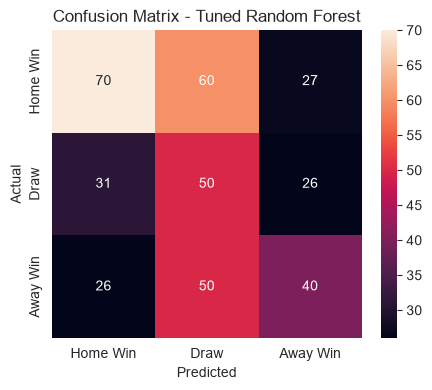

{'Model': 'Tuned Random Forest',
 'Accuracy': 0.42105263157894735,
 'Macro F1': 0.41675490043403024}

In [91]:
best_model = search.best_estimator_

best_result = evaluate_model(
    "Tuned Random Forest",
    best_model,
    X_train_full,
    y_train_full,
    X_test_full,
    y_test_full
)

best_result

 مرحله  ۳

In [92]:
# ============================================================
# Experiment 3: Add Head-to-Head Features
# ============================================================

matches_h2h = matches[[
    "match_api_id",
    "date",
    "home_team_api_id",
    "away_team_api_id",
    "home_team_goal",
    "away_team_goal"
]].copy()

matches_h2h["date"] = pd.to_datetime(matches_h2h["date"])
matches_h2h = matches_h2h.sort_values("date").reset_index(drop=True)


def calculate_h2h_features(matches_data, last_n=5):
    """
    Create Head-to-Head features for each match.
    For each match, only previous matches between the same two teams are used.
    This avoids data leakage.
    """

    h2h_rows = []

    matches_data = matches_data.sort_values("date").reset_index(drop=True)

    for idx, row in matches_data.iterrows():
        current_match_id = row["match_api_id"]
        current_date = row["date"]
        current_home = row["home_team_api_id"]
        current_away = row["away_team_api_id"]

        previous_matches = matches_data[
            (
                (
                    (matches_data["home_team_api_id"] == current_home) &
                    (matches_data["away_team_api_id"] == current_away)
                )
                |
                (
                    (matches_data["home_team_api_id"] == current_away) &
                    (matches_data["away_team_api_id"] == current_home)
                )
            )
            &
            (matches_data["date"] < current_date)
        ].sort_values("date")

        previous_matches = previous_matches.tail(last_n)

        home_points = []
        away_points = []
        goal_diffs = []

        home_wins = 0
        draws = 0
        away_wins = 0

        for _, prev in previous_matches.iterrows():

            # Convert previous match result to the perspective of the CURRENT home team
            if prev["home_team_api_id"] == current_home:
                current_home_goals = prev["home_team_goal"]
                current_away_goals = prev["away_team_goal"]
            else:
                current_home_goals = prev["away_team_goal"]
                current_away_goals = prev["home_team_goal"]

            if current_home_goals > current_away_goals:
                home_points.append(3)
                away_points.append(0)
                home_wins += 1
            elif current_home_goals < current_away_goals:
                home_points.append(0)
                away_points.append(3)
                away_wins += 1
            else:
                home_points.append(1)
                away_points.append(1)
                draws += 1

            goal_diffs.append(current_home_goals - current_away_goals)

        h2h_rows.append({
            "match_api_id": current_match_id,
            "h2h_matches_before": len(previous_matches),
            "h2h_home_points_last5": np.sum(home_points) if len(home_points) > 0 else 0,
            "h2h_away_points_last5": np.sum(away_points) if len(away_points) > 0 else 0,
            "h2h_goal_diff_last5": np.mean(goal_diffs) if len(goal_diffs) > 0 else 0,
            "h2h_home_wins_last5": home_wins,
            "h2h_draws_last5": draws,
            "h2h_away_wins_last5": away_wins
        })

    return pd.DataFrame(h2h_rows)


h2h_features = calculate_h2h_features(matches_h2h, last_n=5)

h2h_features.head()

,match_api_id,h2h_matches_before,h2h_home_points_last5,h2h_away_points_last5,h2h_goal_diff_last5,h2h_home_wins_last5,h2h_draws_last5,h2h_away_wins_last5
0,489043,0,0,0,0.0,0,0,0
1,489044,0,0,0,0.0,0,0,0
2,489045,0,0,0,0.0,0,0,0
3,489047,0,0,0,0.0,0,0,0
4,489048,0,0,0,0.0,0,0,0


In [93]:
# Merge Head-to-Head features with the dataset that already contains form + lineup features

df3 = df2.merge(h2h_features, on="match_api_id", how="left")

h2h_feature_columns = [
    "h2h_matches_before",
    "h2h_home_points_last5",
    "h2h_away_points_last5",
    "h2h_goal_diff_last5",
    "h2h_home_wins_last5",
    "h2h_draws_last5",
    "h2h_away_wins_last5"
]

df3[h2h_feature_columns] = df3[h2h_feature_columns].fillna(0)

df3[h2h_feature_columns].head()

,h2h_matches_before,h2h_home_points_last5,h2h_away_points_last5,h2h_goal_diff_last5,h2h_home_wins_last5,h2h_draws_last5,h2h_away_wins_last5
0,0,0,0,0.0,0,0,0
1,0,0,0,0.0,0,0,0
2,0,0,0,0.0,0,0,0
3,0,0,0,0.0,0,0,0
4,0,0,0,0.0,0,0,0


In [94]:
# Final feature set for Experiment 3

feature_columns_full_h2h = (
    feature_columns_base +
    lineup_feature_columns +
    h2h_feature_columns
)

model_df_h2h = df3[[
    "date", "season", "home_team", "away_team", "result"
] + feature_columns_full_h2h].copy()

model_df_h2h = model_df_h2h.sort_values("date").reset_index(drop=True)

model_df_h2h.head()

,date,season,home_team,away_team,result,home_points_last5,away_points_last5,home_goals_for_last5,away_goals_for_last5,home_goals_against_last5,...,midfield_rating_difference,defense_rating_difference,goalkeeper_rating_difference,h2h_matches_before,h2h_home_points_last5,h2h_away_points_last5,h2h_goal_diff_last5,h2h_home_wins_last5,h2h_draws_last5,h2h_away_wins_last5
0,2008-08-16,2008/2009,Arsenal,West Bromwich Albion,H,0.0,0.0,0.0,0.0,0.0,...,3.666667,8.75,-2.0,0,0,0,0.0,0,0,0
1,2008-08-16,2008/2009,Sunderland,Liverpool,A,0.0,0.0,0.0,0.0,0.0,...,-3.666667,-5.75,-6.0,0,0,0,0.0,0,0,0
2,2008-08-16,2008/2009,West Ham United,Wigan Athletic,H,0.0,0.0,0.0,0.0,0.0,...,5.666667,5.50,0.0,0,0,0,0.0,0,0,0
3,2008-08-16,2008/2009,Everton,Blackburn Rovers,A,0.0,0.0,0.0,0.0,0.0,...,-2.000000,0.25,-2.0,0,0,0,0.0,0,0,0
4,2008-08-16,2008/2009,Middlesbrough,Tottenham Hotspur,H,0.0,0.0,0.0,0.0,0.0,...,-4.666667,-8.50,-9.0,0,0,0,0.0,0,0,0


In [95]:
train_df_h2h = model_df_h2h[
    model_df_h2h["season"].isin([
        "2008/2009",
        "2009/2010",
        "2010/2011",
        "2011/2012",
        "2012/2013",
        "2013/2014"
    ])
]

test_df_h2h = model_df_h2h[
    model_df_h2h["season"] == "2015/2016"
]

X_train_h2h = train_df_h2h[feature_columns_full_h2h]
y_train_h2h = train_df_h2h["result"]

X_test_h2h = test_df_h2h[feature_columns_full_h2h]
y_test_h2h = test_df_h2h["result"]

print("Train H2H:", X_train_h2h.shape)
print("Test H2H:", X_test_h2h.shape)

Train H2H: (2280, 41)
Test H2H: (380, 41)


Dummy Baseline + Form + Lineup + H2H
Accuracy: 0.4131578947368421
Macro F1: 0.19490999379267537

              precision    recall  f1-score   support

           A       0.00      0.00      0.00       116
           D       0.00      0.00      0.00       107
           H       0.41      1.00      0.58       157

    accuracy                           0.41       380
   macro avg       0.14      0.33      0.19       380
weighted avg       0.17      0.41      0.24       380



C:\Users\ghazal\PycharmProjects\PythonProject16\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\ghazal\PycharmProjects\PythonProject16\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\ghazal\PycharmProjects\PythonProject16\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(averag

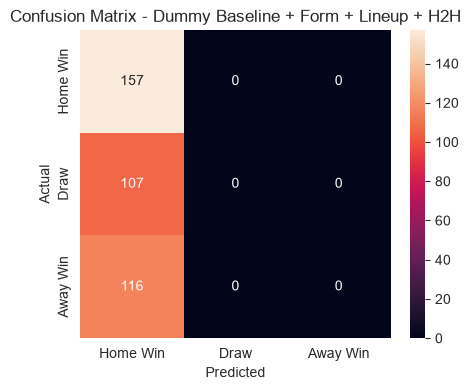

KNN + Form + Lineup + H2H
Accuracy: 0.39473684210526316
Macro F1: 0.37584454447137117

              precision    recall  f1-score   support

           A       0.38      0.38      0.38       116
           D       0.27      0.24      0.26       107
           H       0.47      0.51      0.49       157

    accuracy                           0.39       380
   macro avg       0.38      0.38      0.38       380
weighted avg       0.39      0.39      0.39       380



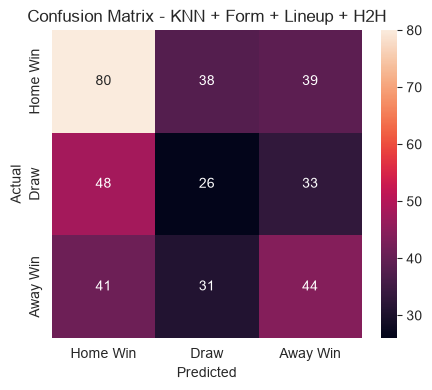

Logistic Regression + Form + Lineup + H2H
Accuracy: 0.4
Macro F1: 0.38733272982272354

              precision    recall  f1-score   support

           A       0.37      0.38      0.37       116
           D       0.27      0.29      0.28       107
           H       0.53      0.49      0.51       157

    accuracy                           0.40       380
   macro avg       0.39      0.39      0.39       380
weighted avg       0.41      0.40      0.40       380



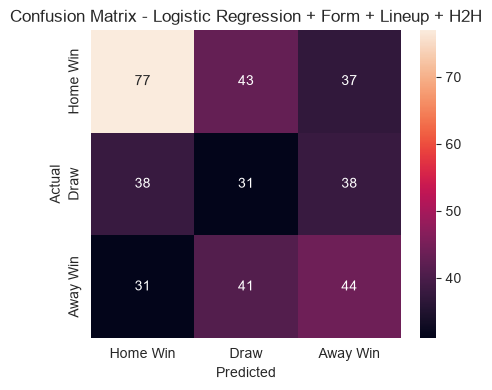

Random Forest + Form + Lineup + H2H
Accuracy: 0.4131578947368421
Macro F1: 0.39311512084987693

              precision    recall  f1-score   support

           A       0.38      0.37      0.38       116
           D       0.31      0.27      0.29       107
           H       0.49      0.54      0.51       157

    accuracy                           0.41       380
   macro avg       0.39      0.39      0.39       380
weighted avg       0.41      0.41      0.41       380



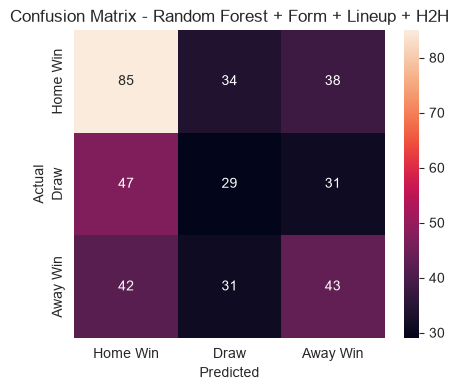

Gradient Boosting + Form + Lineup + H2H
Accuracy: 0.42894736842105263
Macro F1: 0.3485531768222924

              precision    recall  f1-score   support

           A       0.40      0.34      0.36       116
           D       0.33      0.07      0.12       107
           H       0.45      0.74      0.56       157

    accuracy                           0.43       380
   macro avg       0.39      0.38      0.35       380
weighted avg       0.40      0.43      0.38       380



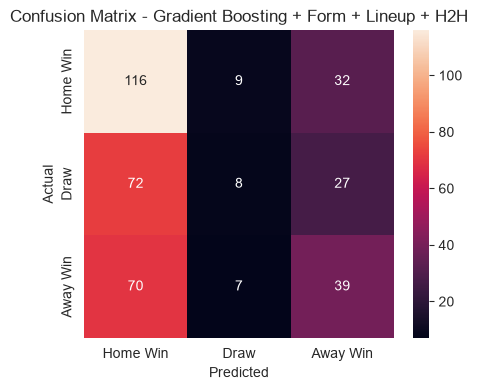

,Model,Accuracy,Macro F1
3,Random Forest + Form + Lineup + H2H,0.413158,0.393115
2,Logistic Regression + Form + Lineup + H2H,0.400000,0.387333
1,KNN + Form + Lineup + H2H,0.394737,0.375845
4,Gradient Boosting + Form + Lineup + H2H,0.428947,0.348553
0,Dummy Baseline + Form + Lineup + H2H,0.413158,0.194910


In [96]:
results_h2h = []

for name, model in models.items():
    result = evaluate_model(
        name + " + Form + Lineup + H2H",
        model,
        X_train_h2h,
        y_train_h2h,
        X_test_h2h,
        y_test_h2h
    )
    results_h2h.append(result)

results_h2h_df = pd.DataFrame(results_h2h)

results_h2h_df.sort_values("Macro F1", ascending=False)

In [97]:
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV

tscv = TimeSeriesSplit(n_splits=5)

param_grid = {
    "n_estimators": [100, 200, 300, 500],
    "max_depth": [5, 10, 15, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"]
}

search_h2h = RandomizedSearchCV(
    RandomForestClassifier(
        random_state=42,
        class_weight="balanced"
    ),
    param_distributions=param_grid,
    n_iter=30,
    cv=tscv,
    scoring="f1_macro",
    random_state=42,
    n_jobs=-1
)

search_h2h.fit(X_train_h2h, y_train_h2h)

print("Best parameters for H2H model:")
print(search_h2h.best_params_)

print("Best CV Macro F1:")
print(search_h2h.best_score_)

Best parameters for H2H model:
{'n_estimators': 100, 'min_samples_split': 2, 'min_samples_leaf': 4, 'max_features': 'log2', 'max_depth': 5}
Best CV Macro F1:
0.4759444049088287


Tuned Random Forest + Form + Lineup + H2H
Accuracy: 0.4105263157894737
Macro F1: 0.4042000684821141

              precision    recall  f1-score   support

           A       0.40      0.34      0.36       116
           D       0.30      0.42      0.35       107
           H       0.54      0.46      0.50       157

    accuracy                           0.41       380
   macro avg       0.41      0.41      0.40       380
weighted avg       0.43      0.41      0.42       380



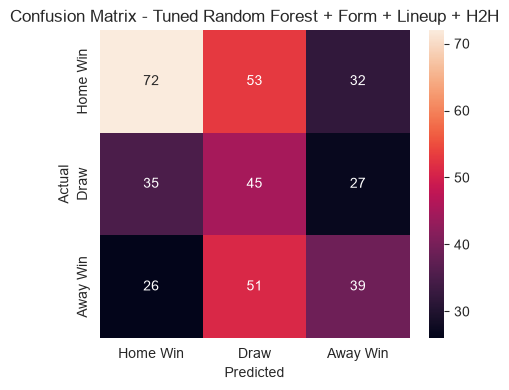

{'Model': 'Tuned Random Forest + Form + Lineup + H2H',
 'Accuracy': 0.4105263157894737,
 'Macro F1': 0.4042000684821141}

In [98]:
best_h2h_model = search_h2h.best_estimator_

h2h_tuned_result = evaluate_model(
    "Tuned Random Forest + Form + Lineup + H2H",
    best_h2h_model,
    X_train_h2h,
    y_train_h2h,
    X_test_h2h,
    y_test_h2h
)

h2h_tuned_result

In [99]:
final_comparison = pd.concat([
    results_base_df.assign(Experiment="Experiment 1: Team Form Only"),
    results_full_df.assign(Experiment="Experiment 2: Team Form + Lineup"),
    results_h2h_df.assign(Experiment="Experiment 3: Team Form + Lineup + H2H")
], ignore_index=True)

final_comparison.sort_values("Macro F1", ascending=False)

,Model,Accuracy,Macro F1,Experiment
8,Random Forest + Lineup Features,0.415789,0.402724,Experiment 2: Team Form + Lineup
13,Random Forest + Form + Lineup + H2H,0.413158,0.393115,Experiment 3: Team Form + Lineup + H2H
7,Logistic Regression + Lineup Features,0.402632,0.392141,Experiment 2: Team Form + Lineup
12,Logistic Regression + Form + Lineup + H2H,0.400000,0.387333,Experiment 3: Team Form + Lineup + H2H
11,KNN + Form + Lineup + H2H,0.394737,0.375845,Experiment 3: Team Form + Lineup + H2H
6,KNN + Lineup Features,0.389474,0.373002,Experiment 2: Team Form + Lineup
2,Logistic Regression,0.400000,0.371886,Experiment 1: Team Form Only
14,Gradient Boosting + Form + Lineup + H2H,0.428947,0.348553,Experiment 3: Team Form + Lineup + H2H
3,Random Forest,0.371053,0.346419,Experiment 1: Team Form Only
4,Gradient Boosting,0.436842,0.336575,Experiment 1: Team Form Only


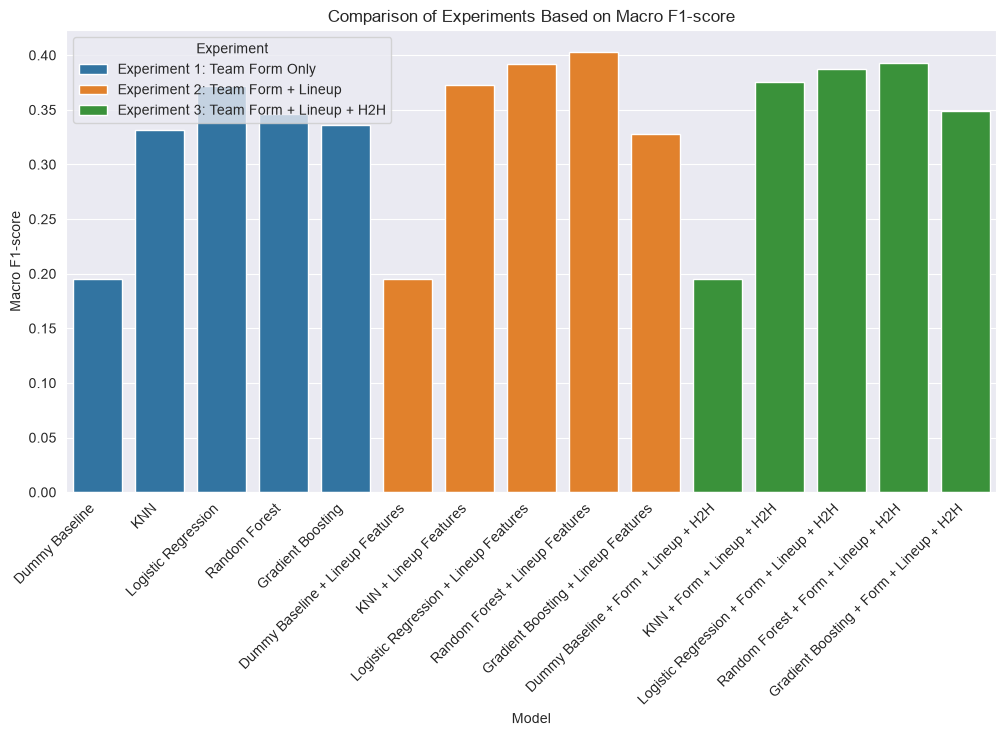

In [100]:
plt.figure(figsize=(12, 6))
sns.barplot(
    data=final_comparison,
    x="Model",
    y="Macro F1",
    hue="Experiment"
)

plt.title("Comparison of Experiments Based on Macro F1-score")
plt.xticks(rotation=45, ha="right")
plt.ylabel("Macro F1-score")
plt.show()